# Statistical Analysis — Multiclass Experiments

This notebook implements the following analysis framework:

| Block | Question | Methods | Test |
|-------|----------|---------|------|
| **A** | SP (all-combos) vs baselines | 22 methods (SP×{3..6}, Voting-hard×{3..6}, Voting-soft×{3..6}, Stacking×{3..6}, RF, XGBoost) | Friedman → Wilcoxon + Holm |
| **B** | Best of each family | 6 methods (BEST-SP, BEST-Voting-hard, BEST-Voting-soft, BEST-Stacking, RF, XGBoost) | Friedman → Nemenyi |
| **C** | All-combos vs top-N | Paired per family × n (4 families × 4 n-values = 16 pairs) | Wilcoxon + Holm |
| **Win-count** | Pairwise dominance | All methods | Per-dataset Wilcoxon + aggregated means |


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon, rankdata
from scikit_posthocs import posthoc_nemenyi_friedman
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", "{:.6f}".format)

C:\Users\jodivaso\AppData\Local\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Configuration

In [2]:
RESULTS_CSV = "results_multiclass2026_04_24_12_37_04.csv" 
ALPHA = 0.05
NS = [3, 4, 5, 6]

# --- Column name mappings (CSV column → display name) ---
# All-combinations ensemble columns (test — primary metric: F1-macro)
ALLCOMB_TEST = {
    **{f"SP-{n}": f"sp_multiclass_{n}_test_macro" for n in NS},
    **{f"Voting-hard-{n}": f"voting_hard_{n}_test_macro" for n in NS},
    **{f"Voting-soft-{n}": f"voting_soft_{n}_test_macro" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_test_macro" for n in NS},
    "RandomForest": "random_forest_test_macro",
    "XGBoost": "xgboost_test_macro",
}

# Top-N ensemble columns (test)
TOPN_TEST = {
    **{f"SP-{n}-topN": f"topN_sp_multiclass_{n}_test_macro" for n in NS},
    **{f"Voting-hard-{n}-topN": f"topN_voting_hard_{n}_test_macro" for n in NS},
    **{f"Voting-soft-{n}-topN": f"topN_voting_soft_{n}_test_macro" for n in NS},
    **{f"Stacking-{n}-topN": f"topN_stacking_{n}_test_macro" for n in NS},
}

# Validation columns (for BEST computation) — all-combinations
ALLCOMB_VAL = {
    **{f"SP-{n}": f"sp_multiclass_{n}_val_macro" for n in NS},
    **{f"Voting-hard-{n}": f"voting_hard_{n}_val_macro" for n in NS},
    **{f"Voting-soft-{n}": f"voting_soft_{n}_val_macro" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_val_macro" for n in NS},
}

# Validation columns — top-N
TOPN_VAL = {
    **{f"SP-{n}-topN": f"topN_sp_multiclass_{n}_val_macro" for n in NS},
    **{f"Voting-hard-{n}-topN": f"topN_voting_hard_{n}_val_macro" for n in NS},
    **{f"Voting-soft-{n}-topN": f"topN_voting_soft_{n}_val_macro" for n in NS},
    **{f"Stacking-{n}-topN": f"topN_stacking_{n}_val_macro" for n in NS},
}

# Sensitivity analysis columns (alternative metrics)
ALLCOMB_TEST_MICRO = {
    **{f"SP-{n}": f"sp_multiclass_{n}_test_micro" for n in NS},
    **{f"Voting-hard-{n}": f"voting_hard_{n}_test_micro" for n in NS},
    **{f"Voting-soft-{n}": f"voting_soft_{n}_test_micro" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_test_micro" for n in NS},
    "RandomForest": "random_forest_test_micro",
    "XGBoost": "xgboost_test_micro",
}

ALLCOMB_TEST_WEIGHTED = {
    **{f"SP-{n}": f"sp_multiclass_{n}_test_weighted" for n in NS},
    **{f"Voting-hard-{n}": f"voting_hard_{n}_test_weighted" for n in NS},
    **{f"Voting-soft-{n}": f"voting_soft_{n}_test_weighted" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_test_weighted" for n in NS},
    "RandomForest": "random_forest_test_weighted",
    "XGBoost": "xgboost_test_weighted",
}

DATASET_COL = "name_dataset"


## 2. Data loading, BEST computation, and aggregation

BEST is computed **per row** (per dataset × run): for each family, select the n with
the highest validation score and report the corresponding test score.  
Then we aggregate by dataset (mean across runs) to get **one observation per method per dataset**.

In [3]:
df_raw = pd.read_csv(RESULTS_CSV)
print(f"Raw data: {df_raw.shape[0]} rows, {df_raw[DATASET_COL].nunique()} datasets")


def compute_best(df, family_prefix, val_dict, test_dict):
    """For each row, pick the n with best val score and return its test score."""
    family_keys = [k for k in val_dict if k.startswith(family_prefix)]
    val_cols = [val_dict[k] for k in family_keys]
    test_cols = [test_dict[k] for k in family_keys]
    best_idx = df[val_cols].values.argmax(axis=1)
    return [df.iloc[i][test_cols[idx]] for i, idx in enumerate(best_idx)]


# Compute BEST for each family (all-combinations)
df_raw["BEST-SP"] = compute_best(df_raw, "SP-", ALLCOMB_VAL, ALLCOMB_TEST)
df_raw["BEST-Voting-hard"] = compute_best(df_raw, "Voting-hard-", ALLCOMB_VAL, ALLCOMB_TEST)
df_raw["BEST-Voting-soft"] = compute_best(df_raw, "Voting-soft-", ALLCOMB_VAL, ALLCOMB_TEST)
df_raw["BEST-Stacking"] = compute_best(df_raw, "Stacking-", ALLCOMB_VAL, ALLCOMB_TEST)

# Compute BEST for each family (top-N)
df_raw["BEST-SP-topN"] = compute_best(df_raw, "SP-", TOPN_VAL, TOPN_TEST)
df_raw["BEST-Voting-hard-topN"] = compute_best(df_raw, "Voting-hard-", TOPN_VAL, TOPN_TEST)
df_raw["BEST-Voting-soft-topN"] = compute_best(df_raw, "Voting-soft-", TOPN_VAL, TOPN_TEST)
df_raw["BEST-Stacking-topN"] = compute_best(df_raw, "Stacking-", TOPN_VAL, TOPN_TEST)

# --- Aggregate by dataset (mean across runs) ---
all_test_cols = (
    list(ALLCOMB_TEST.values()) + list(TOPN_TEST.values())
    + ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft", "BEST-Stacking",
       "BEST-SP-topN", "BEST-Voting-hard-topN", "BEST-Voting-soft-topN", "BEST-Stacking-topN"]
)

df_avg = df_raw.groupby(DATASET_COL)[all_test_cols].mean()
print(f"Aggregated data: {df_avg.shape[0]} datasets (one row per dataset)")

# Build a clean DataFrame with display names as columns
rename_map = {v: k for k, v in {**ALLCOMB_TEST, **TOPN_TEST}.items()}
df_avg = df_avg.rename(columns=rename_map)

# Also aggregate micro and weighted for sensitivity analysis
all_micro_cols = list(ALLCOMB_TEST_MICRO.values())
all_weighted_cols = list(ALLCOMB_TEST_WEIGHTED.values())

df_avg_micro = df_raw.groupby(DATASET_COL)[all_micro_cols].mean()
rename_micro = {v: k for k, v in ALLCOMB_TEST_MICRO.items()}
df_avg_micro = df_avg_micro.rename(columns=rename_micro)

df_avg_weighted = df_raw.groupby(DATASET_COL)[all_weighted_cols].mean()
rename_weighted = {v: k for k, v in ALLCOMB_TEST_WEIGHTED.items()}
df_avg_weighted = df_avg_weighted.rename(columns=rename_weighted)

df_avg.head()

Raw data: 200 rows, 20 datasets
Aggregated data: 20 datasets (one row per dataset)


,SP-3,SP-4,SP-5,SP-6,Voting-hard-3,Voting-hard-4,Voting-hard-5,Voting-hard-6,Voting-soft-3,Voting-soft-4,Voting-soft-5,Voting-soft-6,Stacking-3,Stacking-4,Stacking-5,Stacking-6,RandomForest,XGBoost,SP-3-topN,SP-4-topN,SP-5-topN,SP-6-topN,Voting-hard-3-topN,Voting-hard-4-topN,Voting-hard-5-topN,Voting-hard-6-topN,Voting-soft-3-topN,Voting-soft-4-topN,Voting-soft-5-topN,Voting-soft-6-topN,Stacking-3-topN,Stacking-4-topN,Stacking-5-topN,Stacking-6-topN,BEST-SP,BEST-Voting-hard,BEST-Voting-soft,BEST-Stacking,BEST-SP-topN,BEST-Voting-hard-topN,BEST-Voting-soft-topN,BEST-Stacking-topN
name_dataset,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
datasets_multiclass/GesturePhaseSegmentationProcessed.csv,0.609325,0.605151,0.608648,0.611384,0.561735,0.557204,0.537123,0.484004,0.610546,0.600419,0.588308,0.576768,0.612438,0.612891,0.616974,0.616637,0.588219,0.628329,0.612992,0.603676,0.608930,0.611384,0.545465,0.557204,0.537667,0.484004,0.594558,0.594686,0.589158,0.576768,0.610691,0.612768,0.616768,0.616637,0.612305,0.563343,0.606829,0.615513,0.611579,0.555018,0.594982,0.616196
datasets_multiclass/Indian.csv,0.894063,0.901495,0.912450,0.907547,0.910854,0.909769,0.915277,0.909846,0.898112,0.900478,0.907649,0.909447,0.909501,0.903387,0.902482,0.903244,0.874574,0.875441,0.913219,0.909370,0.909274,0.907547,0.908732,0.914218,0.912111,0.909846,0.901183,0.917741,0.913827,0.909447,0.906018,0.912487,0.894532,0.903244,0.907143,0.908779,0.895342,0.905728,0.905872,0.915195,0.913083,0.910172
datasets_multiclass/JapaneseVowels.csv,0.990855,0.990850,0.990573,0.990762,0.991176,0.988325,0.987543,0.981101,0.990608,0.989258,0.988631,0.986328,0.989467,0.990998,0.990338,0.990895,0.966079,0.977226,0.990220,0.990511,0.991114,0.990762,0.991348,0.987461,0.984241,0.981101,0.991491,0.989875,0.988060,0.986328,0.991210,0.990959,0.990477,0.990895,0.990564,0.990480,0.990666,0.989996,0.990606,0.990833,0.991140,0.990517
datasets_multiclass/USPS.csv,0.968492,0.969991,0.967935,0.968478,0.967287,0.963832,0.963902,0.960155,0.968231,0.967792,0.966794,0.965017,0.968925,0.966433,0.966598,0.968806,0.952534,0.959985,0.969239,0.969141,0.969267,0.968478,0.968677,0.962484,0.959722,0.960155,0.970035,0.967960,0.964806,0.965017,0.970647,0.969297,0.969227,0.968806,0.967988,0.966666,0.968971,0.966086,0.968476,0.967225,0.969850,0.968353
datasets_multiclass/allbp.csv,0.664191,0.655014,0.668483,0.669280,0.662395,0.671941,0.628103,0.654415,0.629282,0.615205,0.569372,0.574288,0.661525,0.650060,0.648131,0.676977,0.522941,0.682153,0.671603,0.649072,0.671171,0.669280,0.714425,0.750105,0.654492,0.654415,0.673491,0.615856,0.612948,0.574288,0.635814,0.617681,0.643945,0.676977,0.669058,0.663475,0.632654,0.646599,0.669595,0.681635,0.634479,0.668630


## 3. Statistical helper functions

In [4]:
def holm_correction(pvalues):
    """Holm step-down correction. Controls FWER like Bonferroni but is strictly more powerful."""
    pvals = np.asarray(pvalues, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    sorted_p = pvals[order]
    adjusted = np.minimum(sorted_p * np.arange(n, 0, -1), 1.0)
    for i in range(1, n):
        adjusted[i] = max(adjusted[i], adjusted[i - 1])
    result = np.empty(n)
    result[order] = adjusted
    return result


def cliffs_delta(x, y):
    """Paired Cliff's delta (nonparametric effect size).

    Interpretation (Romano et al. 2006):
        |d| < 0.147  negligible
        |d| < 0.33   small
        |d| < 0.474  medium
        |d| >= 0.474 large
    """
    d = np.asarray(x) - np.asarray(y)
    return (np.sum(d > 0) - np.sum(d < 0)) / len(d)


def cliffs_delta_label(d):
    """Return a human-readable label for a Cliff's delta value."""
    ad = abs(d)
    if ad < 0.147:
        return "negligible"
    elif ad < 0.33:
        return "small"
    elif ad < 0.474:
        return "medium"
    else:
        return "large"


def pairwise_wilcoxon(df, method_cols, control_prefix=None):
    """Pairwise Wilcoxon signed-rank tests with Holm correction.

    Parameters
    ----------
    df : DataFrame with one row per dataset, columns = method names.
    method_cols : list of column names (display names) to compare.
    control_prefix : if given, only compare methods whose name starts with
                     this prefix against all others. If None, compare all pairs.

    Returns
    -------
    DataFrame with columns: Method1, Method2, p_raw, p_holm, cliff_d, magnitude, Sig.
    """
    pairs, p_raw, deltas = [], [], []

    if control_prefix:
        controls = [m for m in method_cols if m.startswith(control_prefix)]
        others = [m for m in method_cols if not m.startswith(control_prefix)]
        combos = [(c, o) for c in controls for o in others]
    else:
        from itertools import combinations
        combos = list(combinations(method_cols, 2))

    for m1, m2 in combos:
        x, y = df[m1].values, df[m2].values
        diff = x - y
        if np.all(diff == 0):
            p = 1.0
        else:
            _, p = wilcoxon(x, y, alternative="two-sided")
        pairs.append((m1, m2))
        p_raw.append(p)
        deltas.append(cliffs_delta(x, y))

    p_holm = holm_correction(p_raw)

    result = pd.DataFrame({
        "Method 1": [p[0] for p in pairs],
        "Method 2": [p[1] for p in pairs],
        "p (raw)": p_raw,
        "p (Holm)": p_holm,
        "Cliff d": deltas,
        "Magnitude": [cliffs_delta_label(d) for d in deltas],
        "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm],
    })
    return result.sort_values("p (Holm)").reset_index(drop=True)


def friedman_test(df, method_cols):
    """Run Friedman test and print result."""
    arrays = [df[m].values for m in method_cols]
    stat, p = friedmanchisquare(*arrays)
    print(f"Friedman χ² = {stat:.4f},  p = {p:.2e}")
    if p < ALPHA:
        print(f"→ Significant differences detected (p < {ALPHA})")
    else:
        print(f"→ No significant differences (p ≥ {ALPHA})")
    return stat, p

---
## Block A — Main comparison (all combinations)

22 methods: SP-{3..6}, Voting-hard-{3..6}, Voting-soft-{3..6}, Stacking-{3..6}, RF, XGBoost.  
Friedman omnibus → if significant → Wilcoxon pairwise (SP vs all others) with Holm correction.

**Note:** With 22 methods, 4 SP variants × 18 others = 72 pairwise comparisons.
The Holm correction is more conservative than in the binary case (40 comparisons), so
borderline differences may not reach significance.

In [5]:
# Methods for Block A (all-combinations + baselines)
block_a_methods = [
    *[f"SP-{n}" for n in NS],
    *[f"Voting-hard-{n}" for n in NS],
    *[f"Voting-soft-{n}" for n in NS],
    *[f"Stacking-{n}" for n in NS],
    "RandomForest", "XGBoost",
]

print("=" * 60)
print("BLOCK A: Friedman omnibus test")
print("=" * 60)
stat_a, p_a = friedman_test(df_avg, block_a_methods)

if p_a < ALPHA:
    print("\n" + "=" * 60)
    print("BLOCK A: Pairwise Wilcoxon (SP vs others) + Holm correction")
    print("=" * 60)
    table_a = pairwise_wilcoxon(df_avg, block_a_methods, control_prefix="SP-")
    print(table_a.to_string(index=False))

    print("\n" + "=" * 60)
    print("BLOCK A: Mean F1-macro across all datasets")
    print("=" * 60)
    means = df_avg[block_a_methods].mean().sort_values(ascending=False)
    print(means.to_string())

    print("\n" + "=" * 60)
    print("BLOCK A: Mean ranks (lower = better)")
    print("=" * 60)
    ranks = df_avg[block_a_methods].rank(axis=1, ascending=False)
    mean_ranks = ranks.mean().sort_values()
    print(mean_ranks.to_string())

BLOCK A: Friedman omnibus test
Friedman χ² = 58.4982,  p = 1.86e-06
→ Significant differences detected (p < 0.05)

BLOCK A: Pairwise Wilcoxon (SP vs others) + Holm correction
Method 1      Method 2  p (raw)  p (Holm)   Cliff d  Magnitude Sig.
    SP-5 Voting-hard-6 0.000168  0.009399  0.800000      large  Yes
    SP-6 Voting-hard-6 0.000586  0.032206  0.600000      large  Yes
    SP-5 Voting-soft-6 0.001986  0.107220  0.500000      large   No
    SP-4 Voting-hard-6 0.003654  0.193687  0.600000      large   No
    SP-5 Voting-hard-4 0.004860  0.252716  0.500000      large   No
    SP-5 Voting-hard-5 0.004860  0.252716  0.400000     medium   No
    SP-6 Voting-soft-6 0.005581  0.279045  0.400000     medium   No
    SP-6 Voting-hard-5 0.006390  0.313091  0.400000     medium   No
    SP-3 Voting-hard-6 0.007296  0.350189  0.500000      large   No
    SP-6 Voting-hard-3 0.008308  0.390495  0.400000     medium   No
    SP-6 Voting-hard-4 0.008308  0.390495  0.400000     medium   No
    SP-6 

---
## Block B — BEST of each family

6 methods: BEST-SP, BEST-Voting-hard, BEST-Voting-soft, BEST-Stacking, RandomForest, XGBoost.  

Voting-hard and Voting-soft are treated as separate families because they
represent structurally different aggregation mechanisms (majority rule vs
probability averaging).

Nemenyi post-hoc is conditional on the Friedman omnibus being significant.
Wilcoxon pairwise comparisons (BEST-SP vs others) with Holm correction
are reported regardless, since they test specific a-priori hypotheses
and do not depend on the omnibus (García & Herrera, 2008).

In [6]:
block_b_methods = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft",
                   "BEST-Stacking", "RandomForest", "XGBoost"]

print("=" * 60)
print("BLOCK B: Friedman omnibus test")
print("=" * 60)
stat_b, p_b = friedman_test(df_avg, block_b_methods)

# --- Nemenyi: only if Friedman is significant ---
if p_b < ALPHA:
    scores_matrix = df_avg[block_b_methods].values
    nemenyi = posthoc_nemenyi_friedman(scores_matrix)
    nemenyi.index = block_b_methods
    nemenyi.columns = block_b_methods

    print("\nNemenyi p-value matrix:")
    print(nemenyi.round(4).to_string())

    fig, ax = plt.subplots(figsize=(7, 6))
    mask = np.triu(np.ones_like(nemenyi, dtype=bool), k=0)
    sns.heatmap(nemenyi, annot=True, fmt=".4f", cmap="RdYlGn",
                mask=mask, vmin=0, vmax=1, ax=ax,
                linewidths=0.5, square=True)
    ax.set_title("Nemenyi p-values (BEST of family, multiclass)")
    plt.tight_layout()
    plt.savefig("nemenyi_best_of_family_multiclass.pdf", bbox_inches="tight", dpi=300)
    plt.show()
else:
    print(f"\n⚠ Friedman not significant (p={p_b:.4f}). Nemenyi post-hoc skipped.")
    print("  With only 6 methods this is expected when differences are modest.")
    print("  Wilcoxon pairwise tests below are still valid (they test specific hypotheses).")

# --- Descriptive statistics: always computed ---
print("\n" + "=" * 60)
print("BLOCK B: Mean ranks (lower = better)")
print("=" * 60)
ranks_b = df_avg[block_b_methods].rank(axis=1, ascending=False)
mean_ranks_b = ranks_b.mean().sort_values()
print(mean_ranks_b.to_string())

print("\n" + "=" * 60)
print("BLOCK B: Mean F1-macro")
print("=" * 60)
print(df_avg[block_b_methods].mean().sort_values(ascending=False).to_string())

# --- Wilcoxon pairwise: always computed ---
# These are specific a-priori comparisons (BEST-SP vs each other family)
# with proper FWER control via Holm. They do not require the Friedman
# omnibus to be significant (García & Herrera, 2008; Benavoli et al., 2016).
print("\n" + "=" * 60)
print("BLOCK B: Wilcoxon pairwise (BEST-SP vs others) + Holm")
print("=" * 60)
table_b = pairwise_wilcoxon(df_avg, block_b_methods, control_prefix="BEST-SP")
print(table_b.to_string(index=False))


BLOCK B: Friedman omnibus test
Friedman χ² = 8.6994,  p = 1.22e-01
→ No significant differences (p ≥ 0.05)

⚠ Friedman not significant (p=0.1217). Nemenyi post-hoc skipped.
  With only 6 methods this is expected when differences are modest.
  Wilcoxon pairwise tests below are still valid (they test specific hypotheses).

BLOCK B: Mean ranks (lower = better)
BEST-SP            2.900000
BEST-Voting-soft   3.150000
XGBoost            3.200000
BEST-Stacking      3.500000
BEST-Voting-hard   3.850000
RandomForest       4.400000

BLOCK B: Mean F1-macro
XGBoost            0.802055
BEST-SP            0.800548
BEST-Stacking      0.796734
BEST-Voting-soft   0.796291
BEST-Voting-hard   0.793141
RandomForest       0.787124

BLOCK B: Wilcoxon pairwise (BEST-SP vs others) + Holm
Method 1         Method 2  p (raw)  p (Holm)  Cliff d  Magnitude Sig.
 BEST-SP BEST-Voting-hard 0.011236  0.056182 0.450000     medium   No
 BEST-SP    BEST-Stacking 0.053169  0.212677 0.200000      small   No
 BEST-SP     Ra

---
## Block C — All combinations vs top-N

For each family and each n, a paired Wilcoxon test comparing the all-combinations
variant against the top-N variant.  
4 families × 4 values of n = 16 comparisons → Holm correction.

In [7]:
print("=" * 60)
print("BLOCK C: All-combinations vs top-N")
print("=" * 60)

pairs_c, pvals_c, deltas_c = [], [], []

for family in ["SP", "Voting-hard", "Voting-soft", "Stacking"]:
    for n in NS:
        allcomb_name = f"{family}-{n}"
        topn_name = f"{family}-{n}-topN"
        x = df_avg[allcomb_name].values
        y = df_avg[topn_name].values
        diff = x - y
        if np.all(diff == 0):
            p = 1.0
        else:
            _, p = wilcoxon(x, y, alternative="two-sided")
        pairs_c.append((allcomb_name, topn_name))
        pvals_c.append(p)
        deltas_c.append(cliffs_delta(x, y))

p_holm_c = holm_correction(pvals_c)

table_c = pd.DataFrame({
    "All-combos": [p[0] for p in pairs_c],
    "Top-N": [p[1] for p in pairs_c],
    "p (raw)": pvals_c,
    "p (Holm)": p_holm_c,
    "Cliff d": deltas_c,
    "Magnitude": [cliffs_delta_label(d) for d in deltas_c],
    "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm_c],
})
print(table_c.to_string(index=False))

BLOCK C: All-combinations vs top-N
   All-combos              Top-N  p (raw)  p (Holm)   Cliff d  Magnitude Sig.
         SP-3          SP-3-topN 0.527727  1.000000  0.300000      small   No
         SP-4          SP-4-topN 0.177293  1.000000  0.350000     medium   No
         SP-5          SP-5-topN 0.717381  1.000000 -0.300000      small   No
         SP-6          SP-6-topN 1.000000  1.000000  0.000000 negligible   No
Voting-hard-3 Voting-hard-3-topN 0.076618  1.000000  0.250000      small   No
Voting-hard-4 Voting-hard-4-topN 0.981117  1.000000  0.150000      small   No
Voting-hard-5 Voting-hard-5-topN 0.197833  1.000000 -0.250000      small   No
Voting-hard-6 Voting-hard-6-topN 1.000000  1.000000  0.000000 negligible   No
Voting-soft-3 Voting-soft-3-topN 0.243201  1.000000  0.050000 negligible   No
Voting-soft-4 Voting-soft-4-topN 0.295424  1.000000  0.150000      small   No
Voting-soft-5 Voting-soft-5-topN 0.679073  1.000000  0.100000 negligible   No
Voting-soft-6 Voting-soft-6-t

---
## Win-count matrix (per-dataset Wilcoxon)

For each pair of algorithms and each dataset, a Wilcoxon signed-rank test is
performed on the raw (non-averaged) repetitions.  If the difference is significant
at α = 0.05, the method with the higher mean is marked as the winner.

**Note:** with only 10 repetitions per dataset the test has limited power, so these
counts are conservative (a lower bound on actual wins). This is a descriptive
summary, not a formally controlled hypothesis test.

In [8]:
def win_count_matrix(df_raw, method_cols, dataset_col, alpha=0.05):
    """Build the win-count matrix using per-dataset Wilcoxon tests.

    For each (dataset, pair), run a Wilcoxon signed-rank test on the raw
    repetitions.  If significant, the method with higher mean wins.
    """
    methods = list(method_cols.keys())   # display names
    csv_cols = list(method_cols.values()) # CSV column names
    n = len(methods)
    matrix = pd.DataFrame(np.zeros((n, n), dtype=int),
                          index=methods, columns=methods)

    for ds in df_raw[dataset_col].unique():
        sub = df_raw[df_raw[dataset_col] == ds]
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                xi = sub[csv_cols[i]].values
                xj = sub[csv_cols[j]].values
                diff = xi - xj
                if len(diff) < 2 or np.all(diff == 0):
                    continue
                try:
                    _, p = wilcoxon(xi, xj, alternative="two-sided")
                    if p < alpha and xi.mean() > xj.mean():
                        matrix.iloc[i, j] += 1
                except Exception:
                    pass
    return matrix


# Select which methods to include in the win-count matrix
wc_methods = {
    **{f"SP-{n}": f"sp_multiclass_{n}_test_macro" for n in NS},
    "BEST-SP": "BEST-SP",
    **{f"Voting-hard-{n}": f"voting_hard_{n}_test_macro" for n in NS},
    "BEST-Voting-hard": "BEST-Voting-hard",
    **{f"Voting-soft-{n}": f"voting_soft_{n}_test_macro" for n in NS},
    "BEST-Voting-soft": "BEST-Voting-soft",
    **{f"Stacking-{n}": f"stacking_{n}_test_macro" for n in NS},
    "BEST-Stacking": "BEST-Stacking",
    "RandomForest": "random_forest_test_macro",
    "XGBoost": "xgboost_test_macro",
}

print("Computing win-count matrix (this may take a moment)...")
wc = win_count_matrix(df_raw, wc_methods, DATASET_COL, alpha=ALPHA)
print("Done.")
print(wc)

Computing win-count matrix (this may take a moment)...
Done.
                  SP-3  SP-4  SP-5  SP-6  BEST-SP  Voting-hard-3  \
SP-3                 0     0     0     0        0              5   
SP-4                 0     0     1     1        1              4   
SP-5                 1     1     0     0        0              5   
SP-6                 0     1     1     0        0              4   
BEST-SP              2     1     0     0        0              4   
Voting-hard-3        0     0     0     0        0              0   
Voting-hard-4        0     0     0     0        0              0   
Voting-hard-5        0     1     0     0        0              1   
Voting-hard-6        0     0     0     0        0              0   
BEST-Voting-hard     0     0     0     0        0              0   
Voting-soft-3        1     1     1     0        0              3   
Voting-soft-4        1     0     1     0        2              4   
Voting-soft-5        2     0     1     0        0      

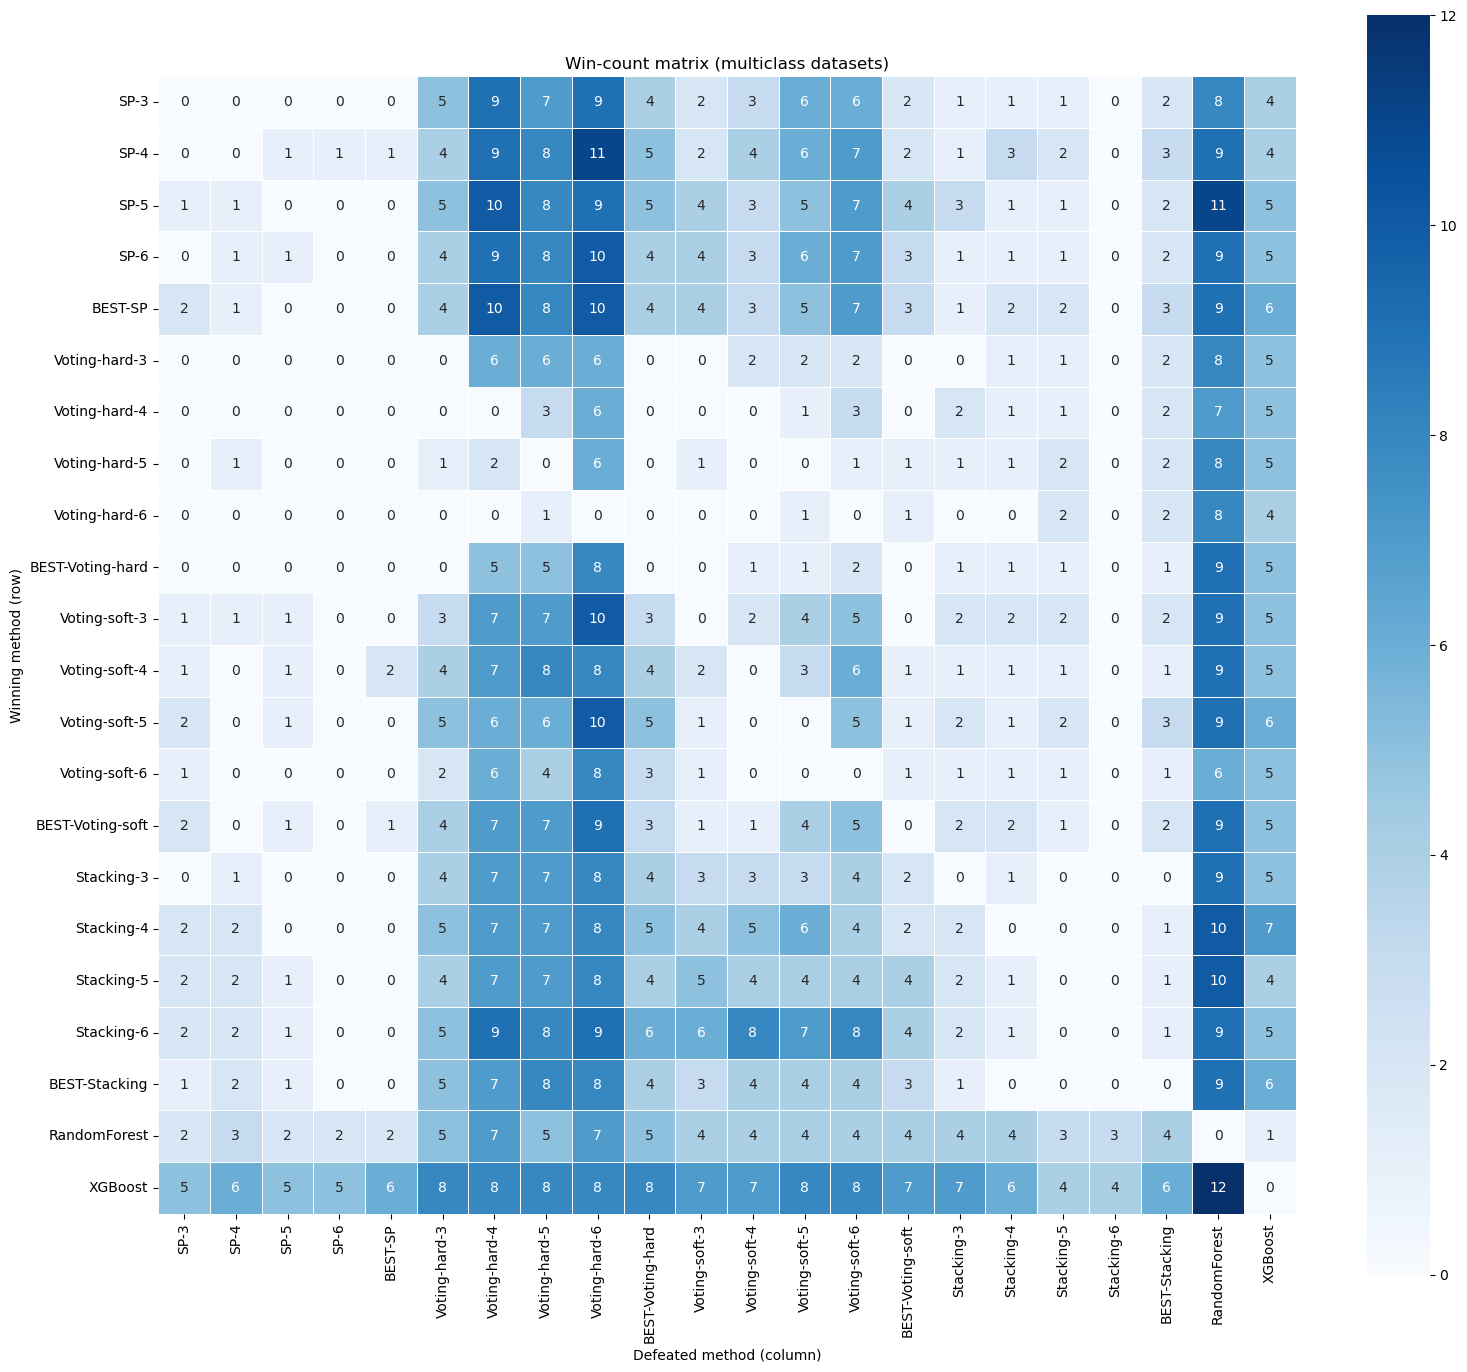

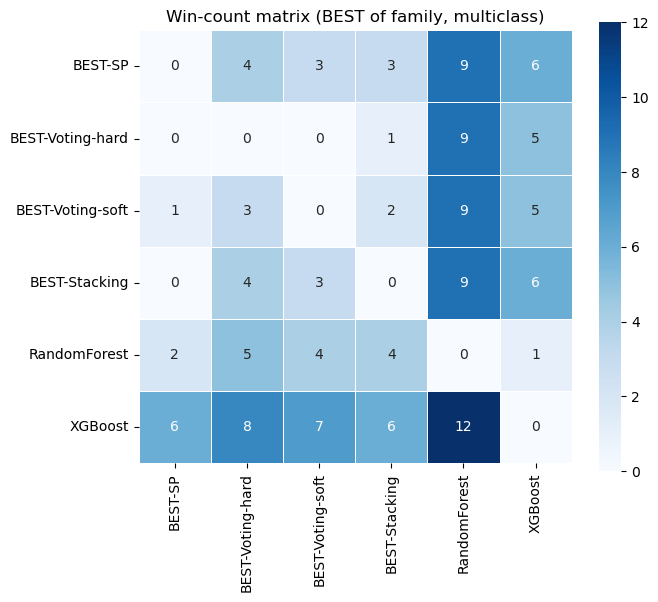

In [9]:
# Full win-count heatmap
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(wc, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (multiclass datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_full_multiclass.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Compact heatmap (BEST + baselines only)
compact_methods = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft",
                   "BEST-Stacking", "RandomForest", "XGBoost"]
wc_compact = wc.loc[compact_methods, compact_methods]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(wc_compact, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (BEST of family, multiclass)")
plt.tight_layout()
plt.savefig("win_count_matrix_small_multiclass.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## Win-count matrix (aggregated means)

For each pair (A, B) and each dataset, simply checks whether A > B using the
mean F1-macro across the 10 runs. No per-dataset significance test — the
statistical significance is already established by the Wilcoxon tests in
Blocks A and B.

Advantages over the per-dataset Wilcoxon version:
- No multiple testing problem (no N_datasets tests per pair)
- Not limited by the low power of n=10 per dataset
- Directly interpretable: "A scored higher in X out of N datasets"


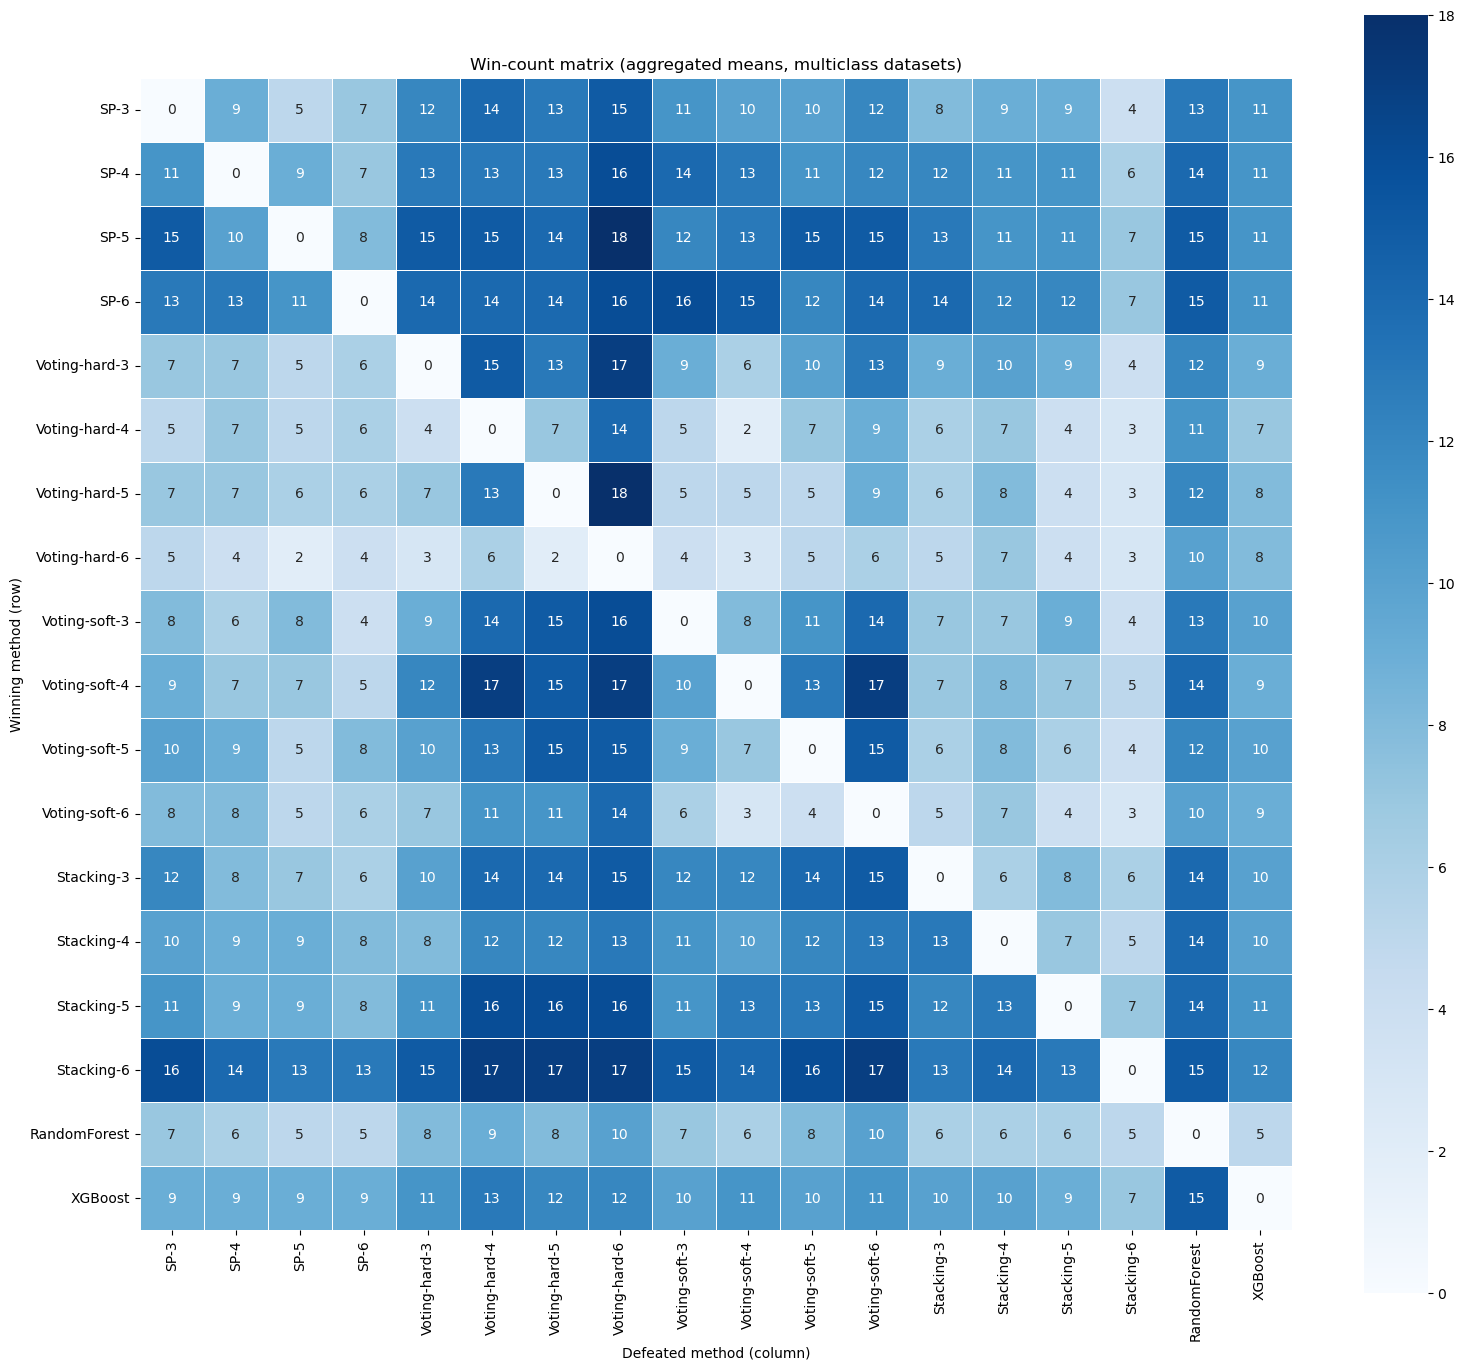

In [10]:
def win_count_matrix_aggregated(df_avg, method_cols):
    """Win-count matrix based on dataset-level mean comparisons.

    Parameters
    ----------
    df_avg : DataFrame with one row per dataset, columns = display-name methods.
    method_cols : list of column names to include.

    Returns
    -------
    DataFrame (n_methods × n_methods) where cell (i, j) = number of datasets
    in which method i scored strictly higher than method j.
    """
    n = len(method_cols)
    matrix = pd.DataFrame(
        np.zeros((n, n), dtype=int),
        index=method_cols, columns=method_cols
    )
    vals = df_avg[method_cols].values

    for i in range(n):
        for j in range(n):
            if i != j:
                matrix.iloc[i, j] = int(np.sum(vals[:, i] > vals[:, j]))
    return matrix


# --- Full win-count (aggregated) ---
wc2_methods = block_a_methods
wc2 = win_count_matrix_aggregated(df_avg, wc2_methods)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(wc2, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (aggregated means, multiclass datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_aggregated_multiclass.pdf", bbox_inches="tight", dpi=300)
plt.show()

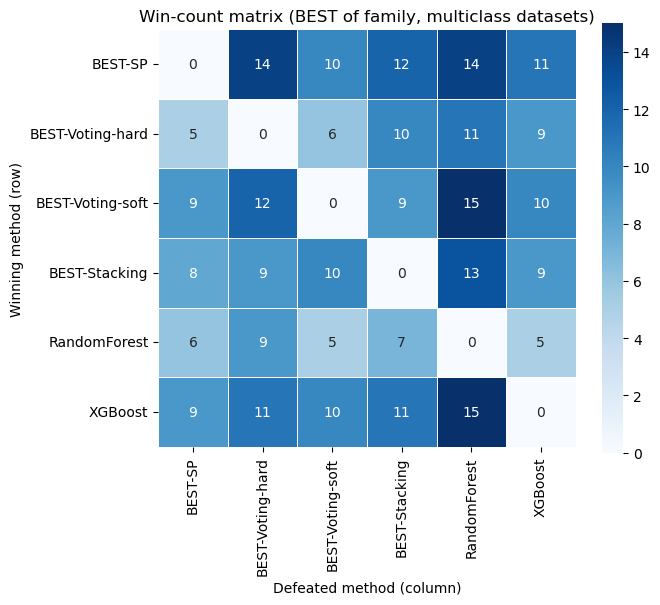

In [11]:
# --- Win-count matrix (BEST of family, aggregated) ---
wc2_best_methods = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft",
                    "BEST-Stacking", "RandomForest", "XGBoost"]
wc2_best = win_count_matrix_aggregated(df_avg, wc2_best_methods)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(wc2_best, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (BEST of family, multiclass datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_best_multiclass.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## LaTeX-ready tables

Tables formatted for direct inclusion in the paper.

In [13]:
# =============================================================================
# LaTeX helper functions + Timing + Block A/B/C tables + BEST computation
# =============================================================================

def to_latex_comparison(table, caption, label):
    """Print a pairwise comparison table in LaTeX format."""
    cols = ["Method 1", "Method 2", "p (Holm)", "Cliff d", "Magnitude", "Sig."]
    t = table[cols].copy()
    t["p (Holm)"] = t["p (Holm)"].apply(
        lambda x: f"{x:.4f}" if x >= 0.0001 else "<0.0001"
    )
    t["Cliff d"] = t["Cliff d"].apply(lambda x: f"{x:.4f}")
    latex = t.to_latex(index=False, escape=False, column_format="llrlll")
    print(f"\\begin{{table*}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table*}}")
    print()


def to_latex_mean_f1(df, methods, caption, label):
    """Print a mean-F1 table in LaTeX format."""
    means = df[methods].mean().sort_values(ascending=False)
    t = pd.DataFrame({"Method": means.index, "Mean F1-macro": means.values})
    t["Mean F1-macro"] = t["Mean F1-macro"].apply(lambda x: f"{x:.6f}")
    latex = t.to_latex(index=False, escape=False, column_format="lr")
    print(f"\\begin{{table}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table}}")
    print()


def format_time(x):
    """Format time: use 4 decimal places for very small values, 2 otherwise."""
    if x < 0.01:
        return f"{x:.4f}"
    elif x < 1:
        return f"{x:.3f}"
    else:
        return f"{x:.2f}"


# ─────────────────────────────────────────────────────────────────────────────
# PART 0: LaTeX tables for Block A
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("LaTeX: Block A — Pairwise comparison")
print("=" * 70)
if p_a < ALPHA:
    to_latex_comparison(
        table_a,
        "Pairwise Wilcoxon tests (SP vs others) with Holm correction on multiclass datasets.",
        "tab:wilcoxon_multiclass"
    )

print("=" * 70)
print("LaTeX: Block A — Mean F1-macro")
print("=" * 70)
to_latex_mean_f1(
    df_avg, block_a_methods,
    "Mean F1-macro across all multiclass datasets.",
    "tab:mean_multiclass"
)


# ─────────────────────────────────────────────────────────────────────────────
# PART 1: Timing table (Mean + Median)
# ─────────────────────────────────────────────────────────────────────────────

# Time column mappings: (display_name, variant_label, n, csv_column)
time_rows = []

# SP all-combos
for n in NS:
    time_rows.append(("Series-Parallel", "All-combos", n, f"time_sp_multiclass_{n}"))
# SP top-N
for n in NS:
    time_rows.append(("Series-Parallel", "Top-N", n, f"time_topN_sp_multiclass_{n}"))
# Voting-hard all-combos
for n in NS:
    time_rows.append(("Voting-hard", "All-combos", n, f"time_voting_hard_{n}"))
# Voting-hard top-N
for n in NS:
    time_rows.append(("Voting-hard", "Top-N", n, f"time_topN_voting_hard_{n}"))
# Voting-soft all-combos
for n in NS:
    time_rows.append(("Voting-soft", "All-combos", n, f"time_voting_soft_{n}"))
# Voting-soft top-N
for n in NS:
    time_rows.append(("Voting-soft", "Top-N", n, f"time_topN_voting_soft_{n}"))
# Stacking all-combos
for n in NS:
    time_rows.append(("Stacking", "All-combos", n, f"time_stacking_{n}"))
# Stacking top-N
for n in NS:
    time_rows.append(("Stacking", "Top-N", n, f"time_topN_stacking_{n}"))
# Baselines (no N)
time_rows.append(("Random Forest", "\u2014", "\u2014", "time_random_forest"))
time_rows.append(("XGBoost", "\u2014", "\u2014", "time_xgboost"))

# BEST rows: sum of times across all N (you need to run all N to select the best)
best_time_configs = [
    ("Series-Parallel", "SP",           "All-combos", "time_sp_multiclass_{n}"),
    ("Voting-hard",     "Voting-hard",   "All-combos", "time_voting_hard_{n}"),
    ("Voting-soft",     "Voting-soft",   "All-combos", "time_voting_soft_{n}"),
    ("Stacking",        "Stacking",      "All-combos", "time_stacking_{n}"),
]

best_time_rows = []
for family_display, family_short, variant, col_tpl in best_time_configs:
    cols = [col_tpl.format(n=n) for n in NS]
    if all(c in df_raw.columns for c in cols):
        best_time_rows.append((family_display, family_short, variant, cols))
    else:
        missing = [c for c in cols if c not in df_raw.columns]
        print(f"WARNING: Missing columns for BEST-{family_short} {variant}: {missing}")

# Build the table
timing_records = []
for method, variant, n, col in time_rows:
    if col in df_raw.columns:
        values = df_raw[col].dropna()
        timing_records.append({
            "Method": method,
            "Variant": variant,
            "N": n,
            "Mean (s)": values.mean(),
            "Median (s)": values.median(),
        })
    else:
        print(f"WARNING: Column '{col}' not found in CSV")

# Add BEST rows (sum across all N per row, then mean/median of the sums)
for family_display, family_short, variant, cols in best_time_rows:
    sum_values = df_raw[cols].sum(axis=1).dropna()
    timing_records.append({
        "Method": f"BEST-{family_short}",
        "Variant": variant,
        "N": "3\u20136",
        "Mean (s)": sum_values.mean(),
        "Median (s)": sum_values.median(),
    })

df_time = pd.DataFrame(timing_records)

print("=" * 70)
print("TIMING TABLE (Mean + Median across all datasets \u00d7 runs)")
print("=" * 70)
print(df_time.to_string(index=False))
print()

# --- LaTeX output ---
print("=" * 70)
print("LaTeX: Timing table")
print("=" * 70)

print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Mean and median time for each method across all multiclass datasets and runs. "
      r"Times for ensemble methods exclude base learner training. "
      r"Times for Random Forest and XGBoost include their Bayesian hyperparameter optimization.}")
print(r"\label{tab:time_multiclass}")
print(r"\begin{tabular}{llcrr}")
print(r"\toprule")
print(r"Method & Variant & $N$ & Mean (s) & Median (s) \\")
print(r"\midrule")

prev_method = None
for _, row in df_time.iterrows():
    if prev_method is not None and row["Method"] != prev_method:
        print(r"\midrule")
    prev_method = row["Method"]

    n_str = str(row["N"]) if row["N"] != "\u2014" else "\u2014"
    mean_str = format_time(row["Mean (s)"])
    med_str = format_time(row["Median (s)"])
    print(f"{row['Method']} & {row['Variant']} & {n_str} & {mean_str} & {med_str} \\\\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()


# ─────────────────────────────────────────────────────────────────────────────
# PART 2: LaTeX tables for Block B (BEST of each family)
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("LaTeX: Block B \u2014 BEST of each family (Wilcoxon + Holm)")
print("=" * 70)

# table_b was computed in Cell 11. Re-generate if needed:
try:
    _ = table_b
except NameError:
    block_b_methods = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft",
                       "BEST-Stacking", "RandomForest", "XGBoost"]
    table_b = pairwise_wilcoxon(df_avg, block_b_methods, control_prefix="BEST-SP")

to_latex_comparison(
    table_b,
    "Block B: Pairwise Wilcoxon tests (BEST-SP vs others) with Holm correction on multiclass datasets.",
    "tab:block_b_multiclass"
)

# --- Nemenyi p-value matrix as LaTeX ---
print("=" * 70)
print("LaTeX: Block B \u2014 Nemenyi p-value matrix")
print("=" * 70)

block_b_methods = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft",
                   "BEST-Stacking", "RandomForest", "XGBoost"]
scores_matrix = df_avg[block_b_methods].values
nemenyi = posthoc_nemenyi_friedman(scores_matrix)
nemenyi.index = block_b_methods
nemenyi.columns = block_b_methods

# Lower-triangular only
print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Nemenyi post-hoc p-values for Block B (BEST of each family) on multiclass datasets.}")
print(r"\label{tab:nemenyi_multiclass}")
n_methods = len(block_b_methods)
col_fmt = "l" + "r" * n_methods
print(f"\\begin{{tabular}}{{{col_fmt}}}")
print(r"\toprule")

abbrev = {
    "BEST-SP": "B-SP",
    "BEST-Voting-hard": "B-V.hard",
    "BEST-Voting-soft": "B-V.soft",
    "BEST-Stacking": "B-Stack",
    "RandomForest": "RF",
    "XGBoost": "XGB",
}
header = " & ".join([""] + [abbrev.get(m, m) for m in block_b_methods])
print(header + r" \\")
print(r"\midrule")

for i, m1 in enumerate(block_b_methods):
    row_label = abbrev.get(m1, m1)
    cells = []
    for j, m2 in enumerate(block_b_methods):
        if j < i:
            val = nemenyi.iloc[i, j]
            cell = f"\\textbf{{{val:.4f}}}" if val < ALPHA else f"{val:.4f}"
            cells.append(cell)
        elif j == i:
            cells.append("\u2014")
        else:
            cells.append("")
    print(row_label + " & " + " & ".join(cells) + r" \\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()

# --- Block B: Mean ranks ---
print("=" * 70)
print("LaTeX: Block B \u2014 Mean ranks")
print("=" * 70)

ranks_b = df_avg[block_b_methods].rank(axis=1, ascending=False)
mean_ranks_b = ranks_b.mean().sort_values()

print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Mean ranks across multiclass datasets (Block B). Lower is better.}")
print(r"\label{tab:ranks_block_b_multiclass}")
print(r"\begin{tabular}{lr}")
print(r"\toprule")
print(r"Method & Mean Rank \\")
print(r"\midrule")
for method, rank in mean_ranks_b.items():
    print(f"{method} & {rank:.4f} \\\\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()

# --- Block B: Mean F1-macro ---
print("=" * 70)
print("LaTeX: Block B \u2014 Mean F1-macro")
print("=" * 70)
to_latex_mean_f1(
    df_avg, block_b_methods,
    "Mean F1-macro for BEST of each family on multiclass datasets.",
    "tab:mean_block_b_multiclass"
)


# ─────────────────────────────────────────────────────────────────────────────
# PART 3: LaTeX table for Block C (All-combos vs top-N)
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("LaTeX: Block C \u2014 All-combinations vs Top-N")
print("=" * 70)

# table_c was computed in Cell 13. Re-generate if needed:
try:
    _ = table_c
except NameError:
    pairs_c, pvals_c, deltas_c = [], [], []
    for family in ["SP", "Voting-hard", "Voting-soft", "Stacking"]:
        for n in NS:
            allcomb_name = f"{family}-{n}"
            topn_name = f"{family}-{n}-topN"
            x = df_avg[allcomb_name].values
            y = df_avg[topn_name].values
            diff = x - y
            if np.all(diff == 0):
                p = 1.0
            else:
                _, p = wilcoxon(x, y, alternative="two-sided")
            pairs_c.append((allcomb_name, topn_name))
            pvals_c.append(p)
            deltas_c.append(cliffs_delta(x, y))
    p_holm_c = holm_correction(pvals_c)
    table_c = pd.DataFrame({
        "All-combos": [p[0] for p in pairs_c],
        "Top-N": [p[1] for p in pairs_c],
        "p (raw)": pvals_c,
        "p (Holm)": p_holm_c,
        "Cliff d": deltas_c,
        "Magnitude": [cliffs_delta_label(d) for d in deltas_c],
        "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm_c],
    })

print(r"\begin{table*}[!tb]")
print(r"\centering")
print(r"\caption{Block C: Paired Wilcoxon tests comparing all-combinations vs top-$N$ "
      r"selection for each ensemble family and size, with Holm correction. "
      r"Positive Cliff's $\delta$ favors the all-combinations variant.}")
print(r"\label{tab:block_c_multiclass}")
print(r"\begin{tabular}{llrlll}")
print(r"\toprule")
print(r"All-combos & Top-N & p (Holm) & Cliff's $\delta$ & Magnitude & Sig. \\")
print(r"\midrule")

prev_family = None
for _, row in table_c.iterrows():
    family = row["All-combos"].rsplit("-", 1)[0]
    if prev_family is not None and family != prev_family:
        print(r"\midrule")
    prev_family = family

    p_holm = row["p (Holm)"]
    p_str = f"{p_holm:.4f}" if p_holm >= 0.0001 else "<0.0001"
    d_str = f"{row['Cliff d']:.4f}"
    sig = row["Sig."]
    print(f"{row['All-combos']} & {row['Top-N']} & {p_str} & {d_str} & "
          f"{row['Magnitude']} & {sig} \\\\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table*}")
print()


# ─────────────────────────────────────────────────────────────────────────────
# PART 4: BEST \u2014 All-combos vs Top-N (additional Block C comparison)
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("BEST: All-combos vs Top-N comparison")
print("=" * 70)

best_allcomb = ["BEST-SP", "BEST-Voting-hard", "BEST-Voting-soft", "BEST-Stacking"]
best_topn    = ["BEST-SP-topN", "BEST-Voting-hard-topN", "BEST-Voting-soft-topN", "BEST-Stacking-topN"]

pairs_best, pvals_best, deltas_best = [], [], []
for ac, tn in zip(best_allcomb, best_topn):
    x = df_avg[ac].values
    y = df_avg[tn].values
    diff = x - y
    if np.all(diff == 0):
        p = 1.0
    else:
        _, p = wilcoxon(x, y, alternative="two-sided")
    pairs_best.append((ac, tn))
    pvals_best.append(p)
    deltas_best.append(cliffs_delta(x, y))

p_holm_best = holm_correction(pvals_best)

table_best = pd.DataFrame({
    "All-combos": [p[0] for p in pairs_best],
    "Top-N": [p[1] for p in pairs_best],
    "Mean All-combos": [df_avg[p[0]].mean() for p in pairs_best],
    "Mean Top-N": [df_avg[p[1]].mean() for p in pairs_best],
    "p (raw)": pvals_best,
    "p (Holm)": p_holm_best,
    "Cliff d": deltas_best,
    "Magnitude": [cliffs_delta_label(d) for d in deltas_best],
    "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm_best],
})
print(table_best.to_string(index=False))


LaTeX: Block A — Pairwise comparison
\begin{table*}[ht]
\centering
\caption{Pairwise Wilcoxon tests (SP vs others) with Holm correction on multiclass datasets.}
\label{tab:wilcoxon_multiclass}
\begin{tabular}{llrlll}
\toprule
Method 1 & Method 2 & p (Holm) & Cliff d & Magnitude & Sig. \\
\midrule
SP-5 & Voting-hard-6 & 0.0094 & 0.8000 & large & Yes \\
SP-6 & Voting-hard-6 & 0.0322 & 0.6000 & large & Yes \\
SP-5 & Voting-soft-6 & 0.1072 & 0.5000 & large & No \\
SP-4 & Voting-hard-6 & 0.1937 & 0.6000 & large & No \\
SP-5 & Voting-hard-4 & 0.2527 & 0.5000 & large & No \\
SP-5 & Voting-hard-5 & 0.2527 & 0.4000 & medium & No \\
SP-6 & Voting-soft-6 & 0.2790 & 0.4000 & medium & No \\
SP-6 & Voting-hard-5 & 0.3131 & 0.4000 & medium & No \\
SP-3 & Voting-hard-6 & 0.3502 & 0.5000 & large & No \\
SP-6 & Voting-hard-3 & 0.3905 & 0.4000 & medium & No \\
SP-6 & Voting-hard-4 & 0.3905 & 0.4000 & medium & No \\
SP-6 & Voting-soft-3 & 0.4246 & 0.6000 & large & No \\
SP-5 & Voting-soft-5 & 0.5315 & 0.5